# Detekcija registarskih oznaka 

* Importovanje potrebnih biblioteka

In [37]:
import os, glob, re, math
import numpy as np
import cv2
import matplotlib.pyplot as plt

import pytesseract
import shutil


* Učitavanje slika iz baze

In [38]:
BASE_DIR = "baza"  
EXTS = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp")

image_paths = []
for ext in EXTS:
    image_paths += glob.glob(os.path.join(BASE_DIR, ext))

image_paths = sorted(image_paths)
print("Broj slika:", len(image_paths))


Broj slika: 15


* Definisanje potrebnih funkcija

In [40]:
def show(title, img, figsize=(10,4)):
    plt.figure(figsize=figsize)
    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(bgr_to_rgb(img))
    plt.title(title)
    plt.axis("off")
    plt.show()

In [41]:
def bgr_to_rgb(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def edge_density(gray_roi):
    ed = cv2.Canny(gray_roi, 50, 150)
    return ed.mean() / 255.0

def detect_plate_bbox(img_bgr):
    h, w = img_bgr.shape[:2]
    img_area = h * w

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.bilateralFilter(gray, 11, 17, 17)

    edged = cv2.Canny(gray, 30, 200)
    edged = cv2.dilate(edged, np.ones((3,3), np.uint8), iterations=1)

    contours, _ = cv2.findContours(edged, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)

    candidates = []

    for c in contours:
        peri = cv2.arcLength(c, True)
        approx = cv2.approxPolyDP(c, 0.02 * peri, True)

        if len(approx) < 4 or len(approx) > 10:
            continue

        x, y, bw, bh = cv2.boundingRect(approx)
        area = bw * bh
        if area < 0.004 * img_area or area > 0.95 * img_area:
            continue

        ar = bw / (bh + 1e-6)
        if ar < 1.6 or ar > 8.5:
            continue

        roi = gray[y:y+bh, x:x+bw]
        if roi.size == 0:
            continue

        ed = edge_density(roi)
        fill = cv2.contourArea(approx) / (area + 1e-6)
        if fill < 0.25:
            continue

        # visina i duzina tablice (odnos)
        height_frac = bh / h
        area_frac = area / img_area
        prior = math.exp(-((height_frac - 0.18) / 0.22) ** 2) * math.exp(-((area_frac - 0.08) / 0.18) ** 2)

        score = area * (0.5 + ed) * fill * (0.2 + prior)
        candidates.append((score, (x, y, bw, bh)))

    if candidates:
        candidates.sort(reverse=True, key=lambda t: t[0])
        return candidates[0][1]
    
    # ako nismo nasli konture, probamo sa Sobel-om
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gx = np.abs(gx)
    gx = (gx / gx.max() * 255).astype(np.uint8) if gx.max() > 0 else gx.astype(np.uint8)
    gx = cv2.GaussianBlur(gx, (5,5), 0)

    _, th = cv2.threshold(gx, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (35,7)), iterations=2)
    th = cv2.dilate(th, np.ones((3,3), np.uint8), iterations=1)

    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    best = None

    for c in contours:
        x, y, bw, bh = cv2.boundingRect(c)
        area = bw * bh
        if area < 0.004 * img_area or area > 0.95 * img_area:
            continue

        ar = bw / (bh + 1e-6)
        if ar < 1.6 or ar > 8.5:
            continue

        roi = gray[y:y+bh, x:x+bw]
        ed = edge_density(roi)

        height_frac = bh / h
        area_frac = area / img_area
        prior = math.exp(-((height_frac - 0.18) / 0.22) ** 2) * math.exp(-((area_frac - 0.08) / 0.18) ** 2)

        score = area * (0.5 + ed) * (0.2 + prior)

        if best is None or score > best[0]:
            best = (score, (x, y, bw, bh))

    return None if best is None else best[1]


def crop_with_padding(img_bgr, bbox, pad=0.06):
    h, w = img_bgr.shape[:2]
    x, y, bw, bh = bbox
    px = int(bw * pad)
    py = int(bh * pad)

    x0 = max(0, x - px); y0 = max(0, y - py)
    x1 = min(w, x + bw + px); y1 = min(h, y + bh + py)
    return img_bgr[y0:y1, x0:x1].copy()

In [42]:
def auto_trim_left(gray):
    # uklanja prazni prostor s leve strane slike.
    col_sum = np.sum(255 - gray, axis=0)
    thresh = 0.05 * np.max(col_sum)

    for i in range(len(col_sum)):
        if col_sum[i] > thresh:
            return gray[:, i:]

    return gray

In [43]:
def tesseract_best_text(img_bin, config):
    data = pytesseract.image_to_data(img_bin, config=config, output_type=pytesseract.Output.DICT)
    texts, confs = [], []
    for t, c in zip(data["text"], data["conf"]):
        if t.strip() == "":
            continue
        try:
            cf = float(c)
        except:
            continue
        if cf < 0:
            continue
        texts.append(t)
        confs.append(cf)

    joined = "".join(texts).upper()
    joined = re.sub(r"[^A-Z0-9-]+", "", joined)
    conf = float(np.mean(confs)) if confs else 0.0
    return joined, conf


def crop_after_blue_prefix(gray, max_cut_frac=0.22, edge_margin=2):
    # adaptivno uklanjanje levog plavog prefiksa (za srb/bih)
    h, w = gray.shape
    left_w = max(20, int(max_cut_frac * w))
    roi = gray[:, :left_w]

    roi_blur = cv2.GaussianBlur(roi, (5,5), 0)

    # Sobel po x tražimo veliku ivicu
    gx = cv2.Sobel(roi_blur, cv2.CV_32F, 1, 0, ksize=3)
    gx = np.abs(gx)

    col_energy = gx.mean(axis=0)

    thr = col_energy.mean() + 2.5 * col_energy.std()

    # najjači pik koji prelazi prag
    x_star = int(np.argmax(col_energy))
    if col_energy[x_star] < thr:
        return gray  

    # ne dozvoli da seče previše (zbog nekih primera)
    if x_star < 10 or x_star > left_w - 2:
        return gray

    cut = min(w-1, x_star + edge_margin)

    before = gray[:, :cut]
    after  = gray[:, cut:]

    # koliko crnih piksela ostaje u prvoj petini posle sečenja
    test = after[:, :max(10, after.shape[1]//6)]
    if np.mean(255 - test) < 2.0:  # prag može 1.5-3.0
        return gray
    
    return gray[:, cut:]

def ocr_plate_robust(plate_bgr):
    
    gray = cv2.cvtColor(plate_bgr, cv2.COLOR_BGR2GRAY)
    gray = crop_after_blue_prefix(gray, edge_margin=1)
    gray = auto_trim_left(gray)

    h, w = gray.shape
    y0, y1 = int(0.05*h), int(0.95*h)
    gray = gray[y0:y1, :]

    # upscale za OCR
    scale = 2.0 if max(gray.shape) < 600 else 1.5
    gray = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)

    gray = cv2.GaussianBlur(gray, (3,3), 0)

    # vise binarizacija
    th1 = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY, 31, 15)
    _, th2 = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    tries = [
        ("adapt", th1),
        ("adapt_inv", 255 - th1),
        ("otsu", th2),
        ("otsu_inv", 255 - th2),
    ]

    def clean(th):
        th = cv2.morphologyEx(th, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT,(2,2)), iterations=1)
        th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT,(3,3)), iterations=1)
        return th

    tries = [(name, clean(th)) for name, th in tries]

    configs = [
        "--oem 3 --psm 7 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-",
        "--oem 3 --psm 6 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-",
    ]

    best = ("", -1e9, None, None)  

    for name, th in tries:
        for cfg in configs:
            txt, conf = tesseract_best_text(th, cfg)

            length = len(txt)
            score = conf
            if 4 <= length <= 12:
                score += 15

            if txt.startswith("-"):
                score -= 5

            if score > best[1]:
                best = (txt, score, name, th)

    return best[0], gray, best[3], best[2], best[1]

In [44]:
digit_map = str.maketrans({
    'O':'0','Q':'0','D':'0',
    'I':'1','L':'1',
    'Z':'2',
    'S':'5',
    'B':'8',
    'G':'6',
})

letter_map = str.maketrans({
    '0':'O','1':'I','2':'Z','5':'S','8':'B','6':'G'
})

def normalize_plate(raw):
    s = re.sub(r"[^A-Z0-9-]+", "", raw.upper()).strip("-")

    # pokušaj: SRB standard (npr BG003-EC)
    m = re.search(r"([A-Z]{2})([A-Z0-9]{3,4})-?([A-Z]{2})", s)
    if m:
        a, mid, b = m.groups()
        a = a.translate(letter_map)[:2]
        b = b.translate(letter_map)[:2]
        mid = re.sub(r"[^0-9]", "", mid.translate(digit_map))
        if len(mid) in (3,4):
            return f"{a}{mid}-{b}"

    # pokušaj: BIH (A12-A-345)
    m = re.search(r"([A-Z])([0-9A-Z]{2})-([A-Z])-([0-9A-Z]{3,4})", s)
    if m:
        l, nn, mid, ddd = m.groups()
        nn = re.sub(r"[^0-9]", "", nn.translate(digit_map))
        ddd = re.sub(r"[^0-9]", "", ddd.translate(digit_map))
        if len(nn) == 2 and 3 <= len(ddd) <= 4:
            return f"{l.translate(letter_map)[:1]}{nn}-{mid.translate(letter_map)[:1]}-{ddd}"

    # BIH (572-I-326)
    m = re.search(r"([0-9A-Z]{3})-([A-Z])-([0-9A-Z]{3})", s)
    if m:
        nnn, mid, ddd = m.groups()
        nnn = re.sub(r"[^0-9]", "", nnn.translate(digit_map))
        ddd = re.sub(r"[^0-9]", "", ddd.translate(digit_map))
        if len(nnn) == 3 and len(ddd) == 3:
            return f"{nnn}-{mid.translate(letter_map)[:1]}-{ddd}"

    return s

In [45]:
def run_on_image(path, show_steps=True):
    img = cv2.imread(path)
    if img is None:
        data = open(path, "rb").read()
        img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)

    bbox = detect_plate_bbox(img)

    vis = img.copy()
    plate_crop = img.copy()

    if bbox is not None:
        x, y, w, h = bbox
        cv2.rectangle(vis, (x,y), (x+w, y+h), (0,255,0), 3)
        plate_crop = crop_with_padding(img, bbox, pad=0.06)

    raw, gray, th, method, score = ocr_plate_robust(plate_crop)
    final = normalize_plate(raw)

    if show_steps:
        print("FILE:", os.path.basename(path))
        print("OCR raw :", raw)
        print("FINAL   :", final)
        print("method  :", method, "| score:", round(score, 2))
        show("1) Original + bbox", vis, figsize=(10,4))
        show("2) Cropped plate", plate_crop, figsize=(10,3))
        show("3) Gray used", gray, figsize=(10,3))
        show("4) Binary used", th, figsize=(10,3))

    return final, raw

* Testiranje

['baza/1.jpg', 'baza/10.jpg', 'baza/11.jpg', 'baza/12.jpeg', 'baza/13.jpeg', 'baza/14.jpeg', 'baza/15.jpeg', 'baza/2.jpg', 'baza/3.jpg', 'baza/4.png', 'baza/5.jpg', 'baza/6.jpg', 'baza/7.webp', 'baza/8.jpg', 'baza/9.jpg']

📷 Obrada slike [12]: 7.webp


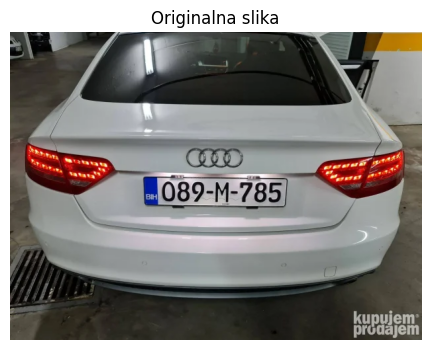

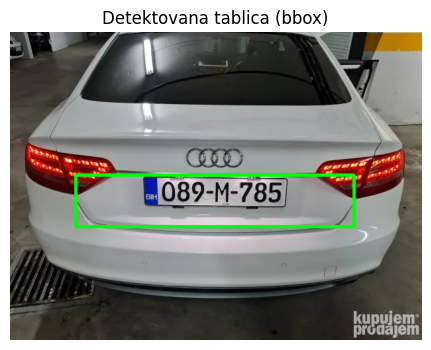

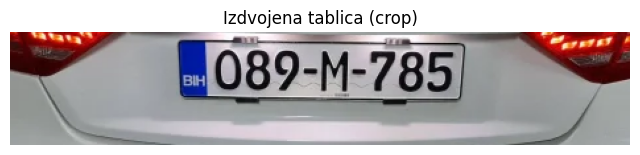

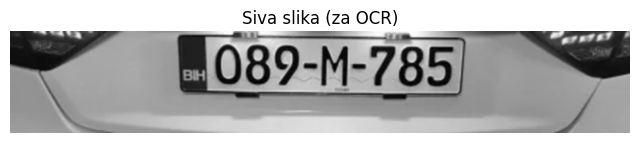

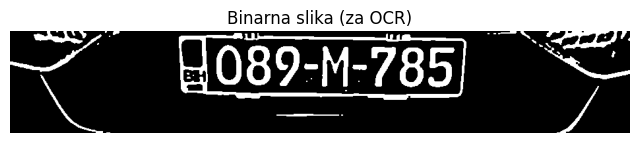

Detektovana tablica: 089-M-785


In [61]:
idx = 12

idx = max(0, min(idx, len(image_paths) - 1))
path = image_paths[idx]

print(image_paths)
print(f"\n📷 Obrada slike [{idx}]: {os.path.basename(path)}")


img = cv2.imread(path)
if img is None:
    data = open(path, "rb").read()
    img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)


bbox = detect_plate_bbox(img)
vis = img.copy()

if bbox is not None:
    x, y, w, h = bbox
    cv2.rectangle(vis, (x,y), (x+w, y+h), (0,255,0), 3)
    plate = crop_with_padding(img, bbox)
else:
    plate = img.copy()

raw, gray, th, method, score = ocr_plate_robust(plate)
final = normalize_plate(raw)


show("Originalna slika", img, figsize=(10,4))
show("Detektovana tablica (bbox)", vis, figsize=(10,4))
show("Izdvojena tablica (crop)", plate, figsize=(8,3))
show("Siva slika (za OCR)", gray, figsize=(8,3))
show("Binarna slika (za OCR)", th, figsize=(8,3))


print("Detektovana tablica:", final)